In [73]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

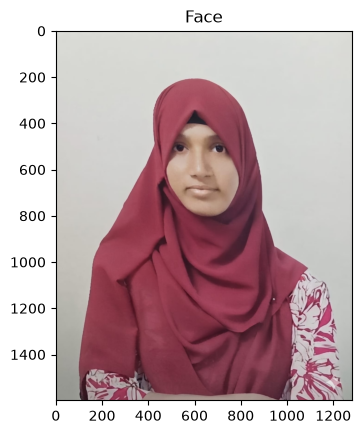

In [74]:
# Load the Face Image
faceImage = cv2.imread('Profile.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [75]:
faceImage.shape

(1599, 1280, 3)

In [76]:
#resized_faceImage.shape
faceImage.shape

(1599, 1280, 3)

Text(0.5, 1.0, 'glassPNG')

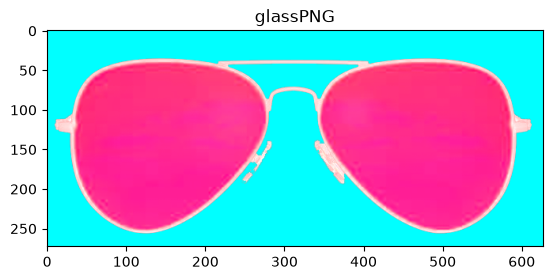

In [77]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [83]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(250, 80))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(80, 250, 4)


In [79]:
# Separate color and alpha channels
glassBGR = glassPNG[:, :, :3]
glassMask1 = glassPNG[:, :, 3]

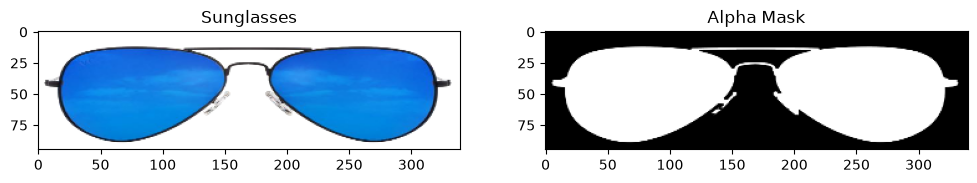

In [80]:
# Display sunglasses and alpha mask
plt.figure(figsize=(12,5))

plt.subplot(121)
plt.imshow(glassBGR[:,:,::-1])
plt.title("Sunglasses")

plt.subplot(122)
plt.imshow(glassMask1, cmap="gray")
plt.title("Alpha Mask")

plt.show()

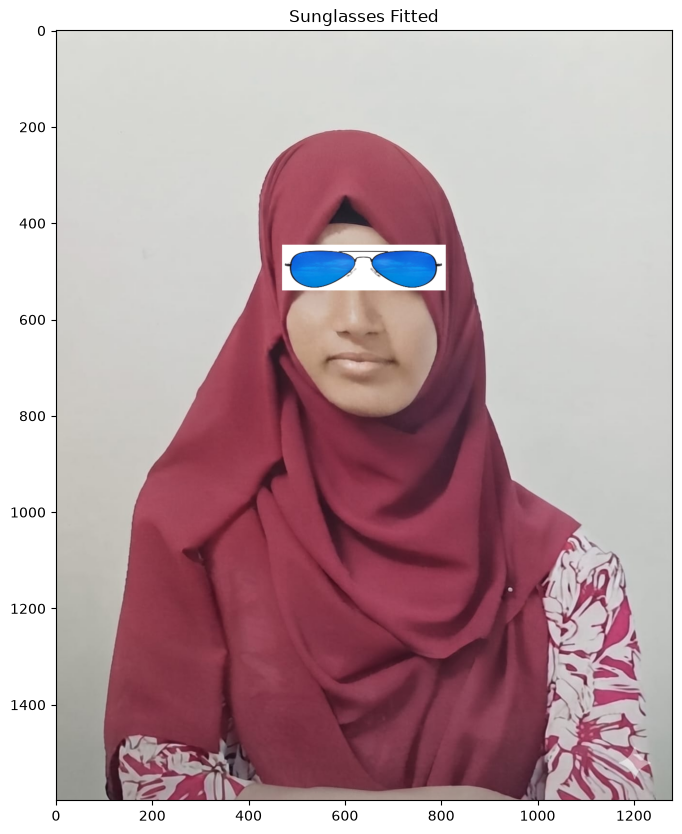

In [86]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Place sunglasses over eyes
faceWithGlassesNaive[445:540,470:810] = glassBGR

# Display
plt.figure(figsize=(8,10))
plt.imshow(faceWithGlassesNaive[:,:,::-1])
plt.title("Sunglasses Fitted")
plt.axis("on")
plt.show()

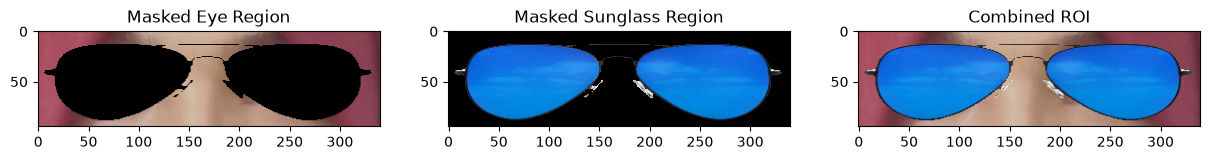

In [81]:
# Create 3-channel mask
glassMask = cv2.merge((glassMask1,
                       glassMask1,
                       glassMask1))

# Convert mask values to 0 and 1
glassMask = np.uint8(glassMask / 255)

# Make a copy of face image
faceWithGlasses = faceImage.copy()

# ==========================================
# EYE REGION COORDINATES FOR YOUR IMAGE
# ==========================================

x = 460   # left-right position
y = 450   # up-down position

h = glassBGR.shape[0]
w = glassBGR.shape[1]

# Extract eye ROI
eyeROI = faceWithGlasses[y:y+h, x:x+w]

# Remove region where glasses will be placed
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Extract glasses using mask
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both images
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Replace eye region with combined image
faceWithGlasses[y:y+h, x:x+w] = eyeRoiFinal

# Intermediate Results
plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(maskedEye[:,:,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass[:,:,::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(eyeRoiFinal[:,:,::-1])
plt.title("Combined ROI")

plt.show()

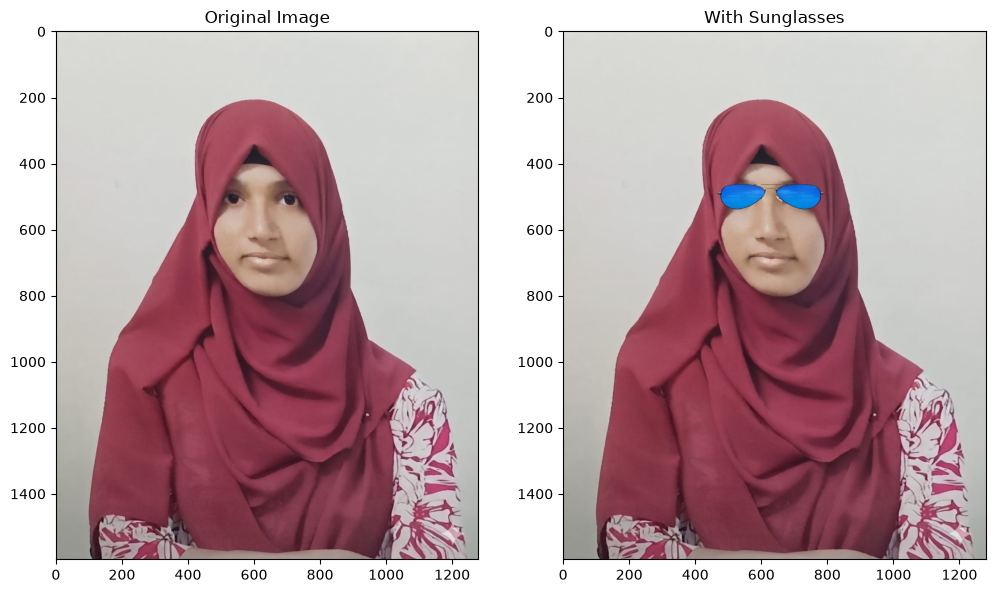

In [87]:
# Final Result
plt.figure(figsize=(12,8))

plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")
plt.axis("on")

plt.subplot(122)
plt.imshow(faceWithGlasses[:,:,::-1])
plt.title("With Sunglasses")
plt.axis("on")

plt.show()